# Axial (Z-Scan) Confocal PL Response Through an Air–Diamond Interface into an NV Ensemble

This notebook models the **axial photoluminescence (PL) response** of a confocal microscope as its focus
is scanned (nominally, via the objective/stage) from air, through the air–diamond interface, through the
diamond bulk, and out the back surface, for a diamond sample containing an NV-center ensemble.

Two doping geometries are modeled:

- **Case A — bulk-doped**: NV centers distributed uniformly throughout the diamond thickness.
- **Case B — buried NV layer**: NV centers confined to a thin layer at a specified depth.

The model captures the dominant physical effects that shape the Z-scan curve:

1. Diffraction-limited Gaussian focusing and beam divergence away from focus (in air and in diamond).
2. The **refractive-index mismatch** between the objective's air-calibrated scan axis and the true focal
   depth inside the higher-index diamond (the reason a translation stage's reading does not equal the
   physical depth probed).
3. **Fresnel reflection/transmission** at the air–diamond interface for both excitation and emission light.
4. The **confocal (illumination × detection) point-spread function**, which falls off faster with defocus
   than a single-pass illumination-only PSF.
5. **Saturation** of the NV emission rate with local excitation intensity.
6. **Beer–Lambert attenuation** of both excitation and emission light along their path through the diamond.

Only `numpy`, `scipy`, and `matplotlib` are used. All parameters are collected in one cell near the top so
the model can later be tuned to match real experimental data.


In [1]:
import numpy as np
import scipy.integrate
import scipy.constants as const
import matplotlib.pyplot as plt

# Consistent color/line styling used throughout the notebook
COLOR_A = "navy"        # Case A: bulk-doped
COLOR_B = "darkorange"  # Case B: buried NV layer
COLOR_INTERFACE = "magenta"
STYLE_INTERFACE = dict(color=COLOR_INTERFACE, linestyle="--", linewidth=1.3, alpha=0.9)

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


## 1. Parameters

All physical and instrumental parameters are collected here. Lengths are worked in **micrometers (µm)**
throughout the notebook (converted to cm only where needed, e.g. for Beer–Lambert absorption which is
conventionally quoted in cm⁻¹). The scan coordinate `z_scan` is the *nominal* (air-calibrated) axial
position of the objective focus, with `z_scan = 0` defined as the front diamond surface.

Notes on specific parameters:

- `I_sat`: the NV saturation intensity is not a single universal number — reported values in the literature
  for NV ensembles under 532 nm excitation typically span roughly **0.1–3 MW/cm²** depending on collection
  optics, NV charge state, and how "saturation" is defined experimentally. It is treated here as a free,
  tunable parameter.
- `alpha_exc_cm`, `alpha_em_cm`: bulk absorption/scattering attenuation of diamond is small for
  high-quality single-crystal material (often < 0.1–1 cm⁻¹ at visible wavelengths, dominated by residual
  N or scattering centers), so both default near zero but are exposed so the effect can be switched on.
- `aberration_coeff`: a heuristic, off-by-default parameter (see Section 3) capturing the qualitative
  extra defocus broadening from depth-dependent spherical aberration that a simple paraxial refraction
  model does not include.


In [2]:
# --- Objective / optics ---
NA = 0.85                  # numerical aperture
WD_mm = 2.0                 # working distance (mm) -- informational only
M = 100                      # magnification -- informational only
lambda_exc_nm = 532.0        # excitation wavelength (nm)
lambda_em_nm = 700.0         # emission wavelength (nm), Stokes-shifted NV- ZPL/PSB emission

# --- Refractive indices ---
n_air = 1.000
n_diamond = 2.417            # at ~532 nm; treat as a tunable parameter

# --- Sample geometry ---
diamond_thickness_um = 500.0     # 0.5 mm plate

# Case B: buried NV layer
nv_layer_depth_um = 150.0        # depth of layer center below front surface
nv_layer_thickness_um = 20.0     # FWHM (Gaussian) or full width (top-hat) of the layer

# --- Excitation / saturation ---
P_mW = 1.0                       # incident laser power (mW), before any interface losses
I_sat_W_cm2 = 1.0e6               # NV saturation intensity (W/cm^2); typical order of magnitude ~1 MW/cm^2

# --- Bulk attenuation (Beer-Lambert), small/near-zero by default ---
alpha_exc_cm = 0.0                # attenuation coefficient at lambda_exc (cm^-1)
alpha_em_cm = 0.0                 # attenuation coefficient at lambda_em (cm^-1)

# --- Aberration heuristic (Section 3), off by default ---
aberration_coeff = 0.0            # extra defocus broadening coefficient (um^-1), see beam_waist_aberrated()

# --- Scan settings (nominal, air-equivalent stage/objective displacement) ---
# NOTE: because of the index-mismatch scaling (Section 3), the *nominal* position of the back
# surface is diamond_thickness_um * (n_air/n_diamond) -- much smaller than diamond_thickness_um
# itself -- so the scan range is set relative to that, not to the true physical thickness.
scan_start_um = -60.0
scan_end_um = diamond_thickness_um * (n_air / n_diamond) + 60.0
scan_step_um = 0.5

print(f"n_diamond / n_air = {n_diamond/n_air:.3f}  (nominal-to-true depth scaling factor past the interface)")


n_diamond / n_air = 2.417  (nominal-to-true depth scaling factor past the interface)


## 2. Diffraction-Limited Focus and Gaussian Beam Propagation

The focused beam is modeled as a Gaussian beam. The 1/e² waist radius at focus is

$$w_0 = \frac{\lambda}{\pi \, \mathrm{NA}}$$

(the Gaussian-optics estimate; the Abbe diffraction limit $0.61\lambda/\mathrm{NA}$ is noted as an
alternative below but is *not* used going forward, since we need a well-defined Rayleigh range for beam
propagation). $w_0$ is computed once for excitation, from $\lambda_\mathrm{exc}$, and used as the geometric
reference for both illumination and (approximately, in this simplified model) collection.

The Rayleigh range in a medium of index $n$ is

$$z_R(n) = \frac{\pi w_0^2 n}{\lambda}$$

and the beam radius as a function of axial distance $z$ from focus is

$$w(z, n) = w_0 \sqrt{1 + \left(\frac{z}{z_R(n)}\right)^2}.$$

Because $z_R \propto n$, the beam **diverges more slowly (stays "in focus" over a longer axial range) in
diamond than in air**, for the same nominal focus quality — this is purely a consequence of the higher
index, before any refraction-at-interface effects are included.


In [3]:
def waist_radius(wavelength_nm, NA):
    """Gaussian-optics focal waist radius w0 (um) for a given excitation wavelength and NA."""
    lam_um = wavelength_nm * 1e-3
    return lam_um / (np.pi * NA)

def waist_radius_abbe(wavelength_nm, NA):
    """Abbe diffraction-limit alternative (um), for reference/comparison only."""
    lam_um = wavelength_nm * 1e-3
    return 0.61 * lam_um / NA

w0 = waist_radius(lambda_exc_nm, NA)
w0_abbe = waist_radius_abbe(lambda_exc_nm, NA)
print(f"Gaussian waist w0        = {w0:.4f} um")
print(f"Abbe diffraction limit    = {w0_abbe:.4f} um  (for comparison only, not used further)")

def rayleigh_range(w0_um, wavelength_nm, n):
    """Rayleigh range z_R (um) in a medium of index n."""
    lam_um = wavelength_nm * 1e-3
    return np.pi * w0_um**2 * n / lam_um

zR_air = rayleigh_range(w0, lambda_exc_nm, n_air)
zR_diamond = rayleigh_range(w0, lambda_exc_nm, n_diamond)
print(f"Rayleigh range in air     = {zR_air:.3f} um")
print(f"Rayleigh range in diamond = {zR_diamond:.3f} um  (factor {zR_diamond/zR_air:.2f}x longer)")

def beam_waist(z_from_focus_um, n, wavelength_nm=lambda_exc_nm, w0_um=None):
    """Gaussian beam radius w(z) at axial distance z_from_focus_um from the focus, in medium n."""
    if w0_um is None:
        w0_um = waist_radius(wavelength_nm, NA)
    zR = rayleigh_range(w0_um, wavelength_nm, n)
    return w0_um * np.sqrt(1.0 + (z_from_focus_um / zR) ** 2)


Gaussian waist w0        = 0.1992 um
Abbe diffraction limit    = 0.3818 um  (for comparison only, not used further)
Rayleigh range in air     = 0.234 um
Rayleigh range in diamond = 0.567 um  (factor 2.42x longer)


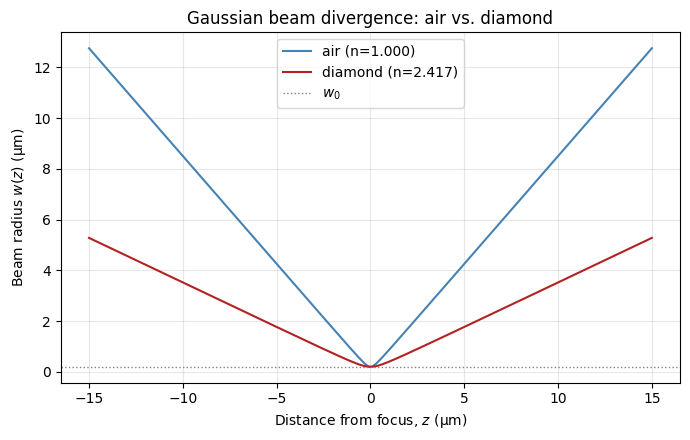

In [4]:
z_rel = np.linspace(-15, 15, 600)  # um, distance from focus

fig, ax = plt.subplots()
ax.plot(z_rel, beam_waist(z_rel, n_air), color="steelblue", label=f"air (n={n_air:.3f})")
ax.plot(z_rel, beam_waist(z_rel, n_diamond), color="firebrick", label=f"diamond (n={n_diamond:.3f})")
ax.axhline(w0, color="gray", linestyle=":", linewidth=1, label=r"$w_0$")
ax.set_xlabel(r"Distance from focus, $z$ (µm)")
ax.set_ylabel(r"Beam radius $w(z)$ (µm)")
ax.set_title("Gaussian beam divergence: air vs. diamond")
ax.legend()
plt.tight_layout()
plt.show()


## 3. Refractive-Index Mismatch: Nominal Scan Position vs. True Focal Depth

This is the central optical-aberration effect in this experiment. The objective is designed/calibrated
assuming it focuses in air (or with an air gap between the last air-side element and the sample). When the
stage or objective is translated by a nominal, air-calibrated distance $\Delta z_\mathrm{nominal}$ **after
the focus has entered the diamond**, the physical focus inside the diamond does *not* move by the same
amount. In the paraxial (low-NA) approximation, marginal rays refract at the interface such that

$$\Delta z_\mathrm{true} \approx \Delta z_\mathrm{nominal} \times \frac{n_\mathrm{diamond}}{n_\mathrm{air}}.$$

So for $n_\mathrm{diamond} \approx 2.417$, a 100 µm stage translation *inside* the diamond actually moves
the true focus by **≈ 240 µm**. Equivalently, the true depth probed grows faster than the stage reading —
the instrument "thinks" it has scanned less than it actually has probed in depth. This mapping applies
**only to the portion of the scan past the diamond interface**; before the interface, the focus is still
entirely in air, so nominal and true position coincide.

**Limitation:** the factor $n_\mathrm{diamond}/n_\mathrm{air}$ is a paraxial (low-NA) approximation. At the
high NA typically used for confocal work, marginal rays refract at different angles than paraxial rays,
producing **depth-dependent spherical aberration**: the focus not only shifts in depth but also
progressively stretches and weakens as the true depth increases, on top of the simple linear rescaling
used here. This notebook does not derive that aberration from full ray optics; instead we expose an
optional, off-by-default heuristic `aberration_coeff` (Section 2's `beam_waist`, extended below) that adds
extra broadening growing with true depth, purely to qualitatively illustrate the trend — it is **not** a
quantitatively derived aberration model.


In [5]:
def nominal_to_true_depth(z_nominal, interface_position=0.0, n1=n_air, n2=n_diamond):
    """Map a nominal (air-calibrated) scan position to the true focal position.

    Before the interface (z_nominal < interface_position): true = nominal (still in air).
    Past the interface: the incremental depth is rescaled by n2/n1 (paraxial approximation).
    """
    z_nominal = np.asarray(z_nominal, dtype=float)
    depth_past_interface = np.clip(z_nominal - interface_position, 0.0, None)
    true_depth = depth_past_interface * (n2 / n1)
    before_interface = np.minimum(z_nominal, interface_position)
    return before_interface + true_depth


def true_focus_depth_into_diamond(z_nominal, interface_position=0.0, n1=n_air, n2=n_diamond):
    """True focus depth measured from the front surface, clipped at 0 (0 if focus still in air)."""
    true_pos = nominal_to_true_depth(z_nominal, interface_position, n1, n2)
    return np.clip(true_pos - interface_position, 0.0, None)


def true_depth_to_nominal(true_depth_um, interface_position=0.0, n1=n_air, n2=n_diamond):
    """Inverse of nominal_to_true_depth, restricted to depths past the interface: the nominal
    (air-calibrated) scan position that produces a given true depth inside the diamond. Used to
    correctly place scan-position annotations (e.g. the back surface) in nominal coordinates.
    """
    return interface_position + true_depth_um * (n1 / n2)


def beam_waist_aberrated(z_grid_um, focus_true_pos_um, n, aberration_coeff_local=0.0,
                          interface_position=0.0, wavelength_nm=lambda_exc_nm, w0_um=None):
    """Beam radius profile at sample positions z_grid_um for a beam focused at focus_true_pos_um,
    with an optional heuristic extra broadening that grows quadratically with true depth into diamond.
    """
    base = beam_waist(z_grid_um - focus_true_pos_um, n, wavelength_nm=wavelength_nm, w0_um=w0_um)
    true_depth = max(focus_true_pos_um - interface_position, 0.0)
    extra = aberration_coeff_local * true_depth ** 2
    return base + extra


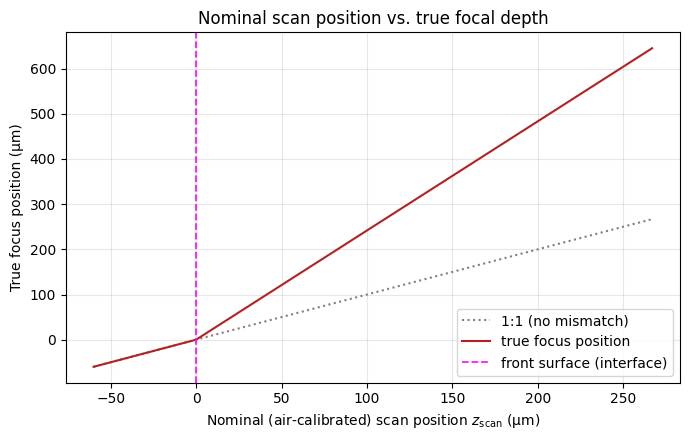

Slope past interface = n_diamond/n_air = 2.417


In [6]:
z_nominal_demo = np.linspace(scan_start_um, scan_end_um, 500)
z_true_demo = nominal_to_true_depth(z_nominal_demo)

fig, ax = plt.subplots()
ax.plot(z_nominal_demo, z_nominal_demo, color="gray", linestyle=":", label="1:1 (no mismatch)")
ax.plot(z_nominal_demo, z_true_demo, color="firebrick", label="true focus position")
ax.axvline(0, **STYLE_INTERFACE, label="front surface (interface)")
ax.set_xlabel(r"Nominal (air-calibrated) scan position $z_\mathrm{scan}$ (µm)")
ax.set_ylabel(r"True focus position (µm)")
ax.set_title("Nominal scan position vs. true focal depth")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Slope past interface = n_diamond/n_air = {n_diamond/n_air:.3f}")


## 4. Fresnel Transmission at the Air–Diamond Interface

At normal incidence, the power reflection and transmission coefficients at an interface between media of
index $n_1$ and $n_2$ are

$$R = \left(\frac{n_2 - n_1}{n_2 + n_1}\right)^2, \qquad T = 1 - R.$$

This is applied twice: once for the excitation beam entering the diamond ($n_1=n_\mathrm{air} \to
n_2=n_\mathrm{diamond}$), and once for the emitted PL light exiting back through the same interface toward
the objective ($n_1=n_\mathrm{diamond} \to n_2=n_\mathrm{air}$). Because $R$ is symmetric in $n_1,n_2$, the
two transmission factors are numerically equal for a single bare interface, but are tracked separately
(`T_exc`, `T_em`) since they act on different beams (excitation power delivered vs. emitted power
collected) and would differ if, e.g., an AR coating were added on only one pass.

For $n_\mathrm{diamond} \approx 2.417$, $R \approx 17\%$ per pass — a real but **secondary** effect compared
to the geometric/confocal defocus and saturation effects modeled below, which change the signal by orders
of magnitude across the scan. The Fresnel factors mainly set an overall scale for the in-diamond signal
relative to a naive (interface-free) model, and combine as $T_\mathrm{exc} \times T_\mathrm{em} \approx
69\%$ throughput for a round trip through the bare interface.


In [7]:
def fresnel_normal_incidence(n1, n2):
    """Normal-incidence power reflectance R and transmittance T going from index n1 into n2."""
    R = ((n2 - n1) / (n2 + n1)) ** 2
    T = 1.0 - R
    return T, R

T_exc, R_exc = fresnel_normal_incidence(n_air, n_diamond)
T_em, R_em = fresnel_normal_incidence(n_diamond, n_air)

print(f"Excitation (air -> diamond): R = {R_exc:.4f}, T = {T_exc:.4f}")
print(f"Emission   (diamond -> air): R = {R_em:.4f}, T = {T_em:.4f}")
print(f"Round-trip throughput T_exc * T_em = {T_exc*T_em:.4f}")


Excitation (air -> diamond): R = 0.1720, T = 0.8280
Emission   (diamond -> air): R = 0.1720, T = 0.8280
Round-trip throughput T_exc * T_em = 0.6856


## 5. Local Excitation Intensity vs. Scan Position and Sample Depth

For a given nominal scan position $z_\mathrm{scan}$, Section 3 gives the true focus position. For any
sample depth $z$ (the coordinate to be integrated over in Section 6), the local beam radius is
$w(z - z_\mathrm{focus,true}, n_\mathrm{local})$, using $n_\mathrm{local}=n_\mathrm{diamond}$ for $z$ inside
the diamond (the only region that matters here, since NV density is zero outside the diamond).

On-axis intensity follows from Gaussian-beam energy conservation — the beam carries constant power, so
peak intensity scales as $1/w(z)^2$:

$$I(z) = I_0 \left(\frac{w_0}{w(z)}\right)^2, \qquad I_0 = \frac{2P}{\pi w_0^2}\; T_\mathrm{exc}$$

where $P$ is the incident laser power and the $T_\mathrm{exc}$ factor accounts for the power lost to
reflection at the interface for the portion of the beam that has entered the diamond.


In [8]:
def peak_intensity_W_cm2(P_mW_local, w0_um_local, transmission=1.0):
    """On-axis peak intensity (W/cm^2) of a focused Gaussian beam of power P_mW_local (mW)
    and waist w0_um_local (um), optionally scaled by an interface transmission factor.
    """
    P_W = P_mW_local * 1e-3
    w0_cm = w0_um_local * 1e-4
    I0 = 2.0 * P_W / (np.pi * w0_cm ** 2)
    return I0 * transmission

I0_diamond = peak_intensity_W_cm2(P_mW, w0, transmission=T_exc)
print(f"Peak on-axis intensity at focus (in diamond, after interface loss) = {I0_diamond:.3e} W/cm^2")
print(f"I0 / I_sat = {I0_diamond / I_sat_W_cm2:.3f}")

def local_intensity(z_sample_um, focus_true_pos_um, n_local=n_diamond, aberration_coeff_local=0.0,
                     interface_position=0.0, I0_W_cm2=I0_diamond, w0_um_local=w0):
    """Local on-axis excitation intensity (W/cm^2) at sample depth z_sample_um for a beam
    focused at focus_true_pos_um.
    """
    w = beam_waist_aberrated(z_sample_um, focus_true_pos_um, n_local, aberration_coeff_local,
                              interface_position, w0_um=w0_um_local)
    return I0_W_cm2 * (w0_um_local / w) ** 2


Peak on-axis intensity at focus (in diamond, after interface loss) = 1.328e+06 W/cm^2
I0 / I_sat = 1.328


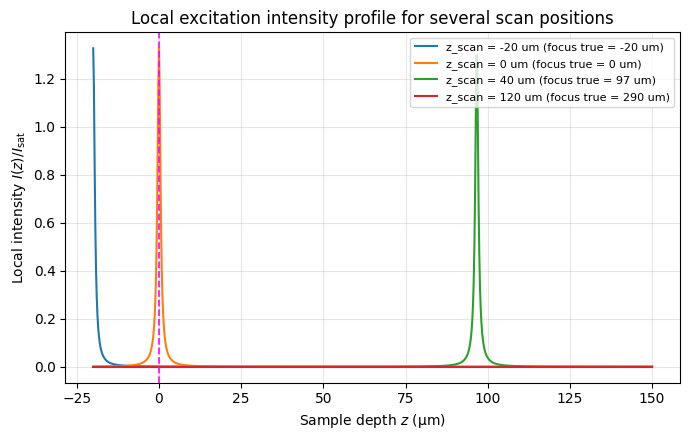

In [9]:
z_depth = np.linspace(-20, diamond_thickness_um * 0.3, 800)
example_scan_positions = [-20, 0, 40, 120]  # nominal scan positions, um

fig, ax = plt.subplots()
for zs in example_scan_positions:
    f_true = nominal_to_true_depth(zs)
    I_profile = local_intensity(z_depth, f_true)
    ax.plot(z_depth, I_profile / I_sat_W_cm2, label=f"z_scan = {zs:.0f} um (focus true = {f_true:.0f} um)")
ax.axvline(0, **STYLE_INTERFACE)
ax.set_xlabel(r"Sample depth $z$ (µm)")
ax.set_ylabel(r"Local intensity $I(z) / I_\mathrm{sat}$")
ax.set_title("Local excitation intensity profile for several scan positions")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 6. NV Density Profile and Integrated Confocal PL Signal

Two normalized (peak = 1) NV volume density profiles $\rho(z)$ are defined:

- **Case A (bulk-doped):** $\rho(z) = 1$ for $0 \le z \le t_\mathrm{diamond}$, else 0.
- **Case B (buried layer):** a Gaussian (or top-hat) layer of specified thickness centered at the
  specified depth, $\approx 0$ elsewhere.

**Illumination-only vs. confocal (illumination × detection) axial response.** A widefield or
illumination-only picture would predict the axial signal falls off as the local excitation intensity does,
i.e. $\propto 1/w(z)^2$. A **true confocal microscope**, however, images the emission back through a
pinhole (or descans onto a small detector) that itself acts as a spatial filter with its own PSF. To lowest
order the detection PSF has the same functional form as the illumination PSF, so the *product* of
illumination and detection efficiency falls off as

$$\frac{1}{w(z)^2} \times \frac{1}{w(z)^2} = \frac{1}{w(z)^4}.$$

This $1/w(z)^4$ scaling — rather than $1/w(z)^2$ — is what gives confocal microscopes their much sharper
axial sectioning, and is used here for the **detection/collection efficiency** factor. The **local
intensity** used to evaluate saturation (Section 7) still uses the physical $1/w(z)^2$ scaling from Section
5, since that is the actual local light intensity seen by the NV centers — only the *collection efficiency*
of already-emitted light back through the confocal aperture gets the extra factor.

The detected PL at a given nominal scan position is then the depth integral

$$\mathrm{PL}(z_\mathrm{scan}) = \int \underbrace{\left(\frac{w_0}{w(z)}\right)^2}_{\text{confocal collection efficiency}}
\cdot \rho(z) \cdot \underbrace{R_\mathrm{emit}(I(z))}_{\text{saturation, Sec. 7}} \cdot
\underbrace{e^{-(\alpha_\mathrm{exc}+\alpha_\mathrm{em})\,z}}_{\text{Beer-Lambert}} \cdot T_\mathrm{em} \; dz$$

evaluated on a fine depth grid with `numpy.trapz` (equivalent, cross-checked below with
`scipy.integrate.quad` for a representative point).


In [10]:
def rho_bulk(z_um, thickness_um=diamond_thickness_um):
    """Case A: uniform NV density throughout the diamond thickness."""
    z_um = np.asarray(z_um, dtype=float)
    return np.where((z_um >= 0.0) & (z_um <= thickness_um), 1.0, 0.0)


def rho_layer(z_um, depth_um=nv_layer_depth_um, thickness_um=nv_layer_thickness_um, profile="gaussian"):
    """Case B: NV density confined to a thin layer centered at depth_um.

    profile='gaussian': thickness_um is interpreted as the FWHM.
    profile='tophat':    thickness_um is interpreted as the full width.
    """
    z_um = np.asarray(z_um, dtype=float)
    if profile == "gaussian":
        sigma = thickness_um / 2.3548  # FWHM -> sigma
        return np.exp(-0.5 * ((z_um - depth_um) / sigma) ** 2)
    elif profile == "tophat":
        return np.where(np.abs(z_um - depth_um) <= thickness_um / 2.0, 1.0, 0.0)
    else:
        raise ValueError("profile must be 'gaussian' or 'tophat'")


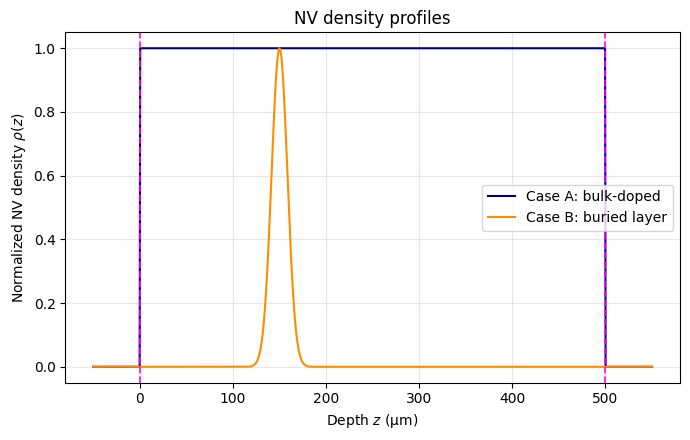

In [11]:
z_check = np.linspace(-50, diamond_thickness_um + 50, 1000)

fig, ax = plt.subplots()
ax.plot(z_check, rho_bulk(z_check), color=COLOR_A, label="Case A: bulk-doped")
ax.plot(z_check, rho_layer(z_check), color=COLOR_B, label="Case B: buried layer")
ax.axvline(0, **STYLE_INTERFACE)
ax.axvline(diamond_thickness_um, **STYLE_INTERFACE)
ax.set_xlabel(r"Depth $z$ (µm)")
ax.set_ylabel(r"Normalized NV density $\rho(z)$")
ax.set_title("NV density profiles")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Saturation Nonlinearity

NV fluorescence per center saturates with local excitation intensity. A standard two-level saturation form
(normalized to a maximum emission rate of 1) is used:

$$R_\mathrm{emit}(I) = \frac{I}{I + I_\mathrm{sat}}.$$

Crucially, this is evaluated using the **local** intensity $I(z)$ from Section 5 — which varies with both
scan position and depth — not the peak on-axis intensity at the current focus.

**On the direction of the effect:** it is tempting to assume saturation *sharpens* the axial response (by
analogy with genuinely contrast-enhancing nonlinear techniques such as STED depletion or two-photon
excitation, which are super-linear or subtractive). Simple single-photon saturation is neither — it is a
*compressive* (concave) nonlinearity: $R_\mathrm{emit}(I)$ rises linearly for $I \ll I_\mathrm{sat}$ but
flattens out and caps at 1 for $I \gg I_\mathrm{sat}$. Cross-checking the two models below (numerically,
not just by assumption) shows this **caps the strong near-focus signal disproportionately more than the
weak off-focus signal, which *reduces* contrast and slightly *broadens* the apparent axial transition**
relative to the purely linear (non-saturating) reference model $R_\mathrm{emit}(I) \propto I$ — the opposite
of the sharpening intuition. This is verified explicitly below by comparing the 10–90% transition width of
the two models at the front surface.

The full PL integral (Section 6) is evaluated below for both cases, using either the saturating or the
purely linear emission-rate model, to compare axial sharpness quantitatively rather than by assumption.


In [12]:
def emission_rate_saturating(I_W_cm2, I_sat_local=I_sat_W_cm2):
    return I_W_cm2 / (I_W_cm2 + I_sat_local)

def emission_rate_linear(I_W_cm2, I_sat_local=I_sat_W_cm2):
    """Linear analogue with the same low-intensity slope as the saturating model, for comparison."""
    return I_W_cm2 / I_sat_local


### Assembling the full PL($z_\mathrm{scan}$) model

The helper `compute_pl_curve` below assembles Sections 3–7 into the full depth integral for an array of
nominal scan positions. A depth grid spanning slightly beyond the diamond on both sides is used so that
Case B layers near the surfaces are not clipped; `rho_func` is zero outside the diamond by construction, so
extending the grid into the air region on either side does not add spurious signal.


In [13]:
def compute_pl_curve(z_scan_array, rho_func, saturating=True, aberration_coeff_local=aberration_coeff,
                      alpha_exc_local=alpha_exc_cm, alpha_em_local=alpha_em_cm, NA_local=NA,
                      P_mW_local=P_mW, I_sat_local=I_sat_W_cm2, thickness_um=diamond_thickness_um,
                      n_diamond_local=n_diamond, n_air_local=n_air, n_grid=4000):
    """Compute the confocal PL(z_scan) curve for a given NV density function.

    Returns an array the same shape as z_scan_array.
    """
    w0_local = waist_radius(lambda_exc_nm, NA_local)
    T_exc_local, _ = fresnel_normal_incidence(n_air_local, n_diamond_local)
    T_em_local, _ = fresnel_normal_incidence(n_diamond_local, n_air_local)
    I0_local = peak_intensity_W_cm2(P_mW_local, w0_local, transmission=T_exc_local)

    z_grid = np.linspace(-50.0, thickness_um + 50.0, n_grid)
    rho_vals = rho_func(z_grid)
    path_cm = np.clip(z_grid, 0.0, None) * 1e-4
    beer_lambert = np.exp(-(alpha_exc_local + alpha_em_local) * path_cm)
    fresnel_factor = np.where(z_grid >= 0.0, T_em_local, 1.0)

    emission_rate_fn = emission_rate_saturating if saturating else emission_rate_linear

    pl = np.empty_like(z_scan_array, dtype=float)
    for i, z_scan in enumerate(z_scan_array):
        f_true = nominal_to_true_depth(z_scan, n1=n_air_local, n2=n_diamond_local)
        w = beam_waist_aberrated(z_grid, f_true, n_diamond_local, aberration_coeff_local,
                                  w0_um=w0_local)
        collection_eff = (w0_local / w) ** 2  # illumination PSF factor
        I_local = I0_local * (w0_local / w) ** 2  # same physical intensity, used for saturation
        rate = emission_rate_fn(I_local, I_sat_local)
        # confocal: collection efficiency appears TWICE (illumination + detection), i.e. 1/w^4 overall,
        # since rate already carries one factor of 1/w^2 through I_local.
        integrand = collection_eff * rho_vals * rate * beer_lambert * fresnel_factor
        pl[i] = np.trapezoid(integrand, z_grid)
    return pl


In [14]:
# Sanity-check numpy.trapz against scipy.integrate.quad for one representative scan position.
z_scan_test = 60.0
f_true_test = nominal_to_true_depth(z_scan_test)
w0_test = waist_radius(lambda_exc_nm, NA)

def integrand_quad(z):
    w = beam_waist_aberrated(np.array([z]), f_true_test, n_diamond, aberration_coeff, w0_um=w0_test)[0]
    collection_eff = (w0_test / w) ** 2
    I_local = I0_diamond * (w0_test / w) ** 2
    rate = emission_rate_saturating(I_local, I_sat_W_cm2)
    path_cm = max(z, 0.0) * 1e-4
    beer = np.exp(-(alpha_exc_cm + alpha_em_cm) * path_cm)
    fresnel = T_em if z >= 0 else 1.0
    return collection_eff * rho_bulk(np.array([z]))[0] * rate * beer * fresnel

quad_result, quad_err = scipy.integrate.quad(integrand_quad, -50, diamond_thickness_um + 50, limit=200)
trapz_result = compute_pl_curve(np.array([z_scan_test]), rho_bulk)[0]
print(f"scipy.integrate.quad result = {quad_result:.6e}  (est. error {quad_err:.1e})")
print(f"trapz (fine grid) result    = {trapz_result:.6e}")
print(f"relative difference         = {abs(quad_result-trapz_result)/quad_result:.2e}")


scipy.integrate.quad result = 5.078457e-01  (est. error 1.5e-08)
trapz (fine grid) result    = 5.078457e-01
relative difference         = 1.27e-10


10-90% transition width, saturating model: 0.900 um
10-90% transition width, linear model:     0.720 um
-> saturation broadens the transition by 25% here


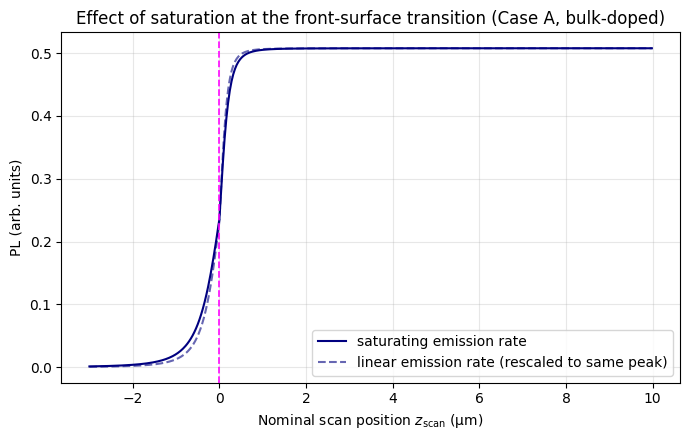

In [15]:
# Zoomed in on the front-surface transition, at fine resolution, so the (sub-micron-to-few-micron)
# difference in transition width between the two models is actually visible.
z_scan_demo = np.arange(-3.0, 10.0, 0.02)

pl_sat = compute_pl_curve(z_scan_demo, rho_bulk, saturating=True)
pl_lin = compute_pl_curve(z_scan_demo, rho_bulk, saturating=False)
pl_lin_norm = pl_lin / np.max(pl_lin) * np.max(pl_sat)  # normalize for shape comparison

def transition_width_10_90(y, x):
    y0, y1 = y.min(), y.max()
    lo, hi = y0 + 0.1 * (y1 - y0), y0 + 0.9 * (y1 - y0)
    x_lo = x[np.argmax(y >= lo)]
    x_hi = x[np.argmax(y >= hi)]
    return x_hi - x_lo

w_sat = transition_width_10_90(pl_sat, z_scan_demo)
w_lin = transition_width_10_90(pl_lin_norm, z_scan_demo)
print(f"10-90% transition width, saturating model: {w_sat:.3f} um")
print(f"10-90% transition width, linear model:     {w_lin:.3f} um")
print(f"-> saturation {'broadens' if w_sat > w_lin else 'sharpens'} the transition by "
      f"{abs(w_sat/w_lin - 1)*100:.0f}% here")

fig, ax = plt.subplots()
ax.plot(z_scan_demo, pl_sat, color=COLOR_A, label="saturating emission rate")
ax.plot(z_scan_demo, pl_lin_norm, color=COLOR_A, linestyle="--", alpha=0.6,
        label="linear emission rate (rescaled to same peak)")
ax.axvline(0, **STYLE_INTERFACE)
ax.set_xlabel(r"Nominal scan position $z_\mathrm{scan}$ (µm)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("Effect of saturation at the front-surface transition (Case A, bulk-doped)")
ax.legend()
plt.tight_layout()
plt.show()


## 8. Full Z-Scan Simulation: Case A vs. Case B

The nominal scan is swept from well above the diamond surface, through the front interface, through the
bulk, to the back surface and beyond, using the full model (saturating emission, confocal $1/w^4$
collection, Fresnel losses, Beer–Lambert attenuation). Four characteristic regions are annotated, with
their nominal scan positions computed via `true_depth_to_nominal` (Section 3) — note that because of the
index-mismatch scaling, the *nominal* position of the back surface is only
$t_\mathrm{diamond}\times(n_\mathrm{air}/n_\mathrm{diamond}) \approx t_\mathrm{diamond}/2.4$, not
$t_\mathrm{diamond}$ itself:

1. **Above the diamond** — no NVs in the focal volume, baseline signal ≈ 0.
2. **Front surface** — the confocal volume first fully overlaps with NV-containing material, at the point
   of least accumulated defocus/aberration.
3. **Bulk** — depth-dependent falloff from confocal defocus/aberration and attenuation.
4. **Back surface and beyond** — signal returns to baseline once the focus passes out of the NV-containing
   region entirely.

**A note on what actually produces the depth-dependent falloff.** With the global default
`aberration_coeff = 0` and near-zero attenuation (Section 1), the axial PSF is *extremely* short compared
to the diamond thickness (its Rayleigh range in diamond is well under 1 µm for typical NA, vs. hundreds of
µm of diamond) — so by simple translational invariance, a confocal scan through a *uniform* bulk region
would give an almost perfectly flat plateau, not a decaying one, except for the sharp step transitions at
the two surfaces. The peak-and-decay shape typically seen in real NV-diamond Z-scans (and sketched in the
reference figure) comes from **depth-dependent spherical aberration** growing as the true focus goes
deeper — exactly the effect `aberration_coeff` was introduced to capture (Section 3), and/or from
attenuation in lower-quality material. To make that illustrated here rather than only in the Section 9(d)
sweep, this demonstration turns on a small, representative `aberration_coeff_demo` (chosen to give a
visible but not extreme falloff); the pure `aberration_coeff = 0` case is shown explicitly in Section 9(d)
for comparison.


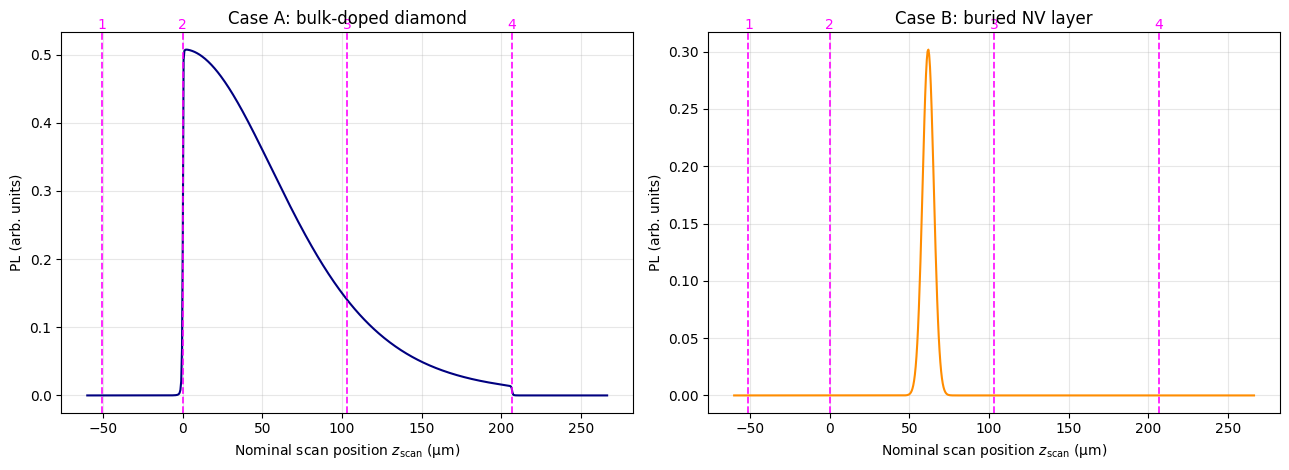

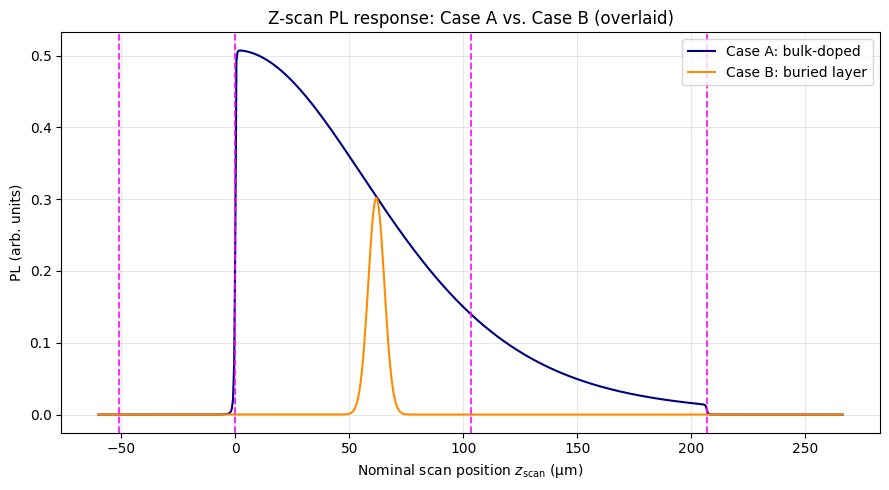

In [16]:
z_scan = np.arange(scan_start_um, scan_end_um, scan_step_um)

# Small representative aberration coefficient for THIS illustrative demo only (see markdown above);
# the notebook-wide default in Section 1 remains aberration_coeff = 0.
aberration_coeff_demo = 2e-6  # um^-1; chosen to give a visible but not extreme bulk falloff

pl_caseA = compute_pl_curve(z_scan, rho_bulk, aberration_coeff_local=aberration_coeff_demo)
pl_caseB = compute_pl_curve(z_scan, rho_layer, aberration_coeff_local=aberration_coeff_demo)

# Annotated positions matching the reference sketch, correctly converted to NOMINAL scan
# coordinates (positions 3 and 4 are physical depths, so they must go through true_depth_to_nominal):
pos1 = scan_start_um + 0.15 * (0 - scan_start_um)         # "above diamond"
pos2 = 0.0                                                  # front surface (nominal == true here)
pos3 = true_depth_to_nominal(diamond_thickness_um / 2.0)   # mid-bulk (true depth -> nominal)
pos4 = true_depth_to_nominal(diamond_thickness_um)         # back surface (true depth -> nominal)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=False)

axes[0].plot(z_scan, pl_caseA, color=COLOR_A)
axes[0].set_title("Case A: bulk-doped diamond")

axes[1].plot(z_scan, pl_caseB, color=COLOR_B)
axes[1].set_title("Case B: buried NV layer")

for ax in axes:
    for pos, label in zip([pos1, pos2, pos3, pos4], ["1", "2", "3", "4"]):
        ax.axvline(pos, **STYLE_INTERFACE)
        ax.text(pos, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 1, label,
                color=COLOR_INTERFACE, fontsize=10, ha="center", va="bottom")
    ax.set_xlabel(r"Nominal scan position $z_\mathrm{scan}$ (µm)")
    ax.set_ylabel("PL (arb. units)")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(z_scan, pl_caseA, color=COLOR_A, label="Case A: bulk-doped")
ax.plot(z_scan, pl_caseB, color=COLOR_B, label="Case B: buried layer")
for pos, label in zip([pos1, pos2, pos3, pos4], ["1", "2", "3", "4"]):
    ax.axvline(pos, **STYLE_INTERFACE)
ax.set_xlabel(r"Nominal scan position $z_\mathrm{scan}$ (µm)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("Z-scan PL response: Case A vs. Case B (overlaid)")
ax.legend()
plt.tight_layout()
plt.show()


**Interpreting the curve shape:**

- **Position 1 (above the diamond):** the focal volume contains no NVs, so PL ≈ 0 aside from any
  numerical tail from the confocal PSF's finite wings.
- **Position 2 (front surface):** as the true focus crosses the front surface, the confocal excitation and
  collection volumes first fully overlap with dense NV-containing material *while the focus is still
  sharpest* (essentially zero depth-dependent aberration accumulated right at the surface) — this
  combination produces the peak right at the surface. For Case B with the layer near the surface, this
  peak instead reflects the layer itself once the true focus reaches it.
- **Position 3 (bulk):** for Case A, signal persists through the bulk but decays with depth, because the
  `aberration_coeff_demo` broadening (growing with true depth) progressively weakens and defocuses the
  collected signal, and (if enabled) Beer–Lambert attenuation reduces both excitation reaching depth $z$
  and emission escaping from it. For Case B, this region instead shows a distinct, roughly layer-shaped
  peak centered near the *true* depth of the buried layer (not the nominal depth — see Section 3), whose
  height is somewhat higher than Case A's corresponding local value since all the NV density is
  concentrated where the (still-limited) defocus is smallest.
- **Position 4 (back surface and beyond):** once the true focus passes the back surface, $\rho(z)=0$ over
  the entire confocal volume again and the signal returns to baseline.

Recall (per the note above the plot) that this depth-dependent falloff through the bulk is *not* present
in the pure zero-aberration, zero-attenuation model — it is switched on here via `aberration_coeff_demo`
purely for illustration. Section 9(d) below shows the `aberration_coeff = 0` case explicitly (flat bulk
plateau) alongside nonzero values, isolating this parameter's effect.


## 9. Parameter Sensitivity Exploration

A few sweeps illustrate how the Z-scan shape responds to key parameters. Each sweep is kept in its own
cell with a short prediction before the plot.


### (a) Numerical aperture

**Expectation:** a higher NA gives a smaller focal waist $w_0$. Since the heuristic aberration broadening
`aberration_coeff_demo` (Section 8) adds a fixed, NA-independent extra width at a given true depth, that
fixed extra broadening becomes proportionally *more* significant against a smaller $w_0$ baseline for
higher NA — so, using the same `aberration_coeff_demo` as Section 8, higher NA should show a **narrower,
more pronounced surface peak** but also a **faster relative falloff into the bulk** for Case A. (With
`aberration_coeff = 0`, by contrast, all curves would be depth-independent top-hats differing only in
overall height — the falloff trend specifically comes from the aberration term.)


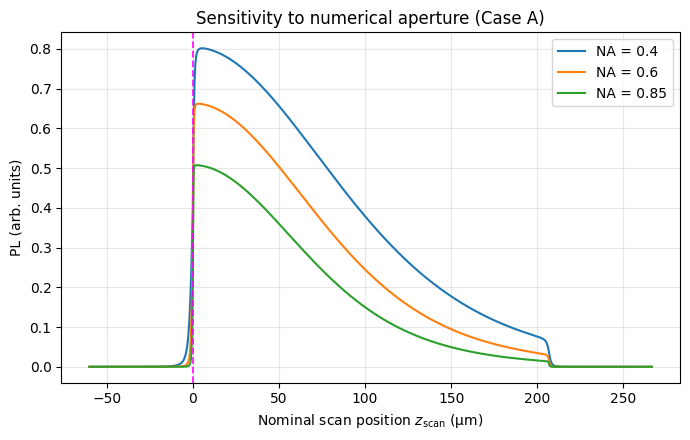

In [17]:
NA_values = [0.4, 0.6, 0.85]
fig, ax = plt.subplots()
for NA_val in NA_values:
    pl = compute_pl_curve(z_scan, rho_bulk, NA_local=NA_val, aberration_coeff_local=aberration_coeff_demo)
    ax.plot(z_scan, pl, label=f"NA = {NA_val}")
ax.axvline(0, **STYLE_INTERFACE)
ax.set_xlabel(r"Nominal scan position $z_\mathrm{scan}$ (µm)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("Sensitivity to numerical aperture (Case A)")
ax.legend()
plt.tight_layout()
plt.show()


### (b) Laser power / saturation intensity ratio

**Expectation (per Section 7):** increasing $P/I_\mathrm{sat}$ pushes more of the near-focus signal into the
capped (saturated) regime while the wings (where $I \ll I_\mathrm{sat}$) stay essentially linear/unaffected.
Since capping the strong near-focus contribution more than the weak wings *reduces contrast*, higher
$P/I_\mathrm{sat}$ should make the front-surface transition **broader**, not sharper — zoomed in below, at
fixed `aberration_coeff = 0` so only the saturation effect is visible.


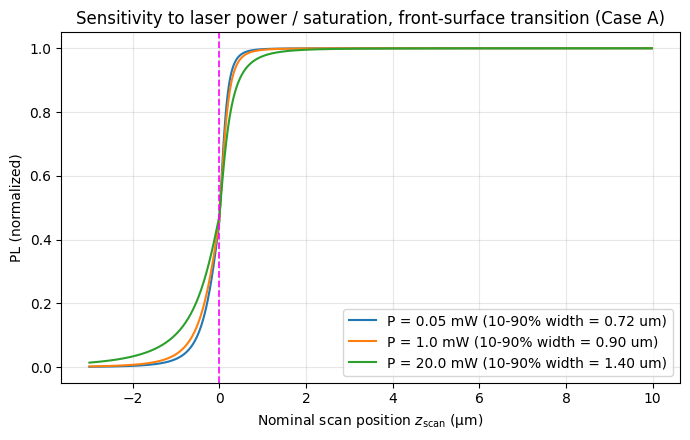

In [18]:
power_values_mW = [0.05, 1.0, 20.0]  # spans well below to well above saturation at I_sat_W_cm2
z_scan_zoom = np.arange(-3.0, 10.0, 0.02)
fig, ax = plt.subplots()
for P_val in power_values_mW:
    pl = compute_pl_curve(z_scan_zoom, rho_bulk, P_mW_local=P_val)
    pl_norm = pl / np.max(pl)
    w = transition_width_10_90(pl_norm, z_scan_zoom)
    ax.plot(z_scan_zoom, pl_norm, label=f"P = {P_val} mW (10-90% width = {w:.2f} um)")
ax.axvline(0, **STYLE_INTERFACE)
ax.set_xlabel(r"Nominal scan position $z_\mathrm{scan}$ (µm)")
ax.set_ylabel("PL (normalized)")
ax.set_title("Sensitivity to laser power / saturation, front-surface transition (Case A)")
ax.legend()
plt.tight_layout()
plt.show()


### (c) Buried layer depth and thickness (Case B)

**Expectation:** the PL peak's *nominal* scan position should track the layer's *true* depth via the
inverse of the Section 3 mapping (nominal $\approx$ true depth $\times n_\mathrm{air}/n_\mathrm{diamond}$),
and the peak width should track the layer thickness — illustrating how a Z-scan could be used to locate an
unknown buried NV layer.


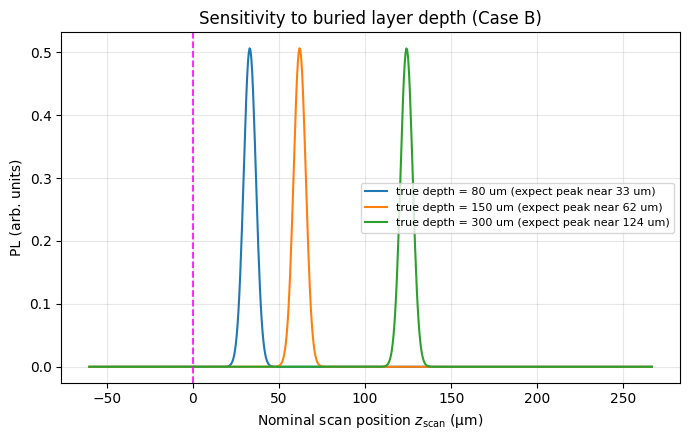

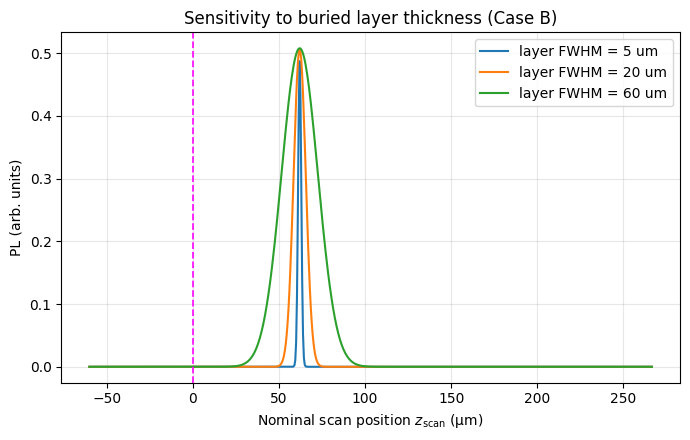

In [19]:
layer_depths_um = [80, 150, 300]
fig, ax = plt.subplots()
for depth in layer_depths_um:
    rho_func = lambda z, d=depth: rho_layer(z, depth_um=d, thickness_um=nv_layer_thickness_um)
    pl = compute_pl_curve(z_scan, rho_func)
    expected_nominal = depth * (n_air / n_diamond)
    ax.plot(z_scan, pl, label=f"true depth = {depth} um (expect peak near {expected_nominal:.0f} um)")
ax.axvline(0, **STYLE_INTERFACE)
ax.set_xlabel(r"Nominal scan position $z_\mathrm{scan}$ (µm)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("Sensitivity to buried layer depth (Case B)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

layer_thicknesses_um = [5, 20, 60]
fig, ax = plt.subplots()
for thick in layer_thicknesses_um:
    rho_func = lambda z, t=thick: rho_layer(z, depth_um=nv_layer_depth_um, thickness_um=t)
    pl = compute_pl_curve(z_scan, rho_func)
    ax.plot(z_scan, pl, label=f"layer FWHM = {thick} um")
ax.axvline(0, **STYLE_INTERFACE)
ax.set_xlabel(r"Nominal scan position $z_\mathrm{scan}$ (µm)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("Sensitivity to buried layer thickness (Case B)")
ax.legend()
plt.tight_layout()
plt.show()


### (d) Aberration coefficient

**Expectation:** turning on the heuristic depth-dependent aberration broadening (Section 3) should leave
the near-surface signal largely unchanged but progressively **broaden and weaken** the signal from deeper
in the bulk, since the extra broadening term grows quadratically with true depth.


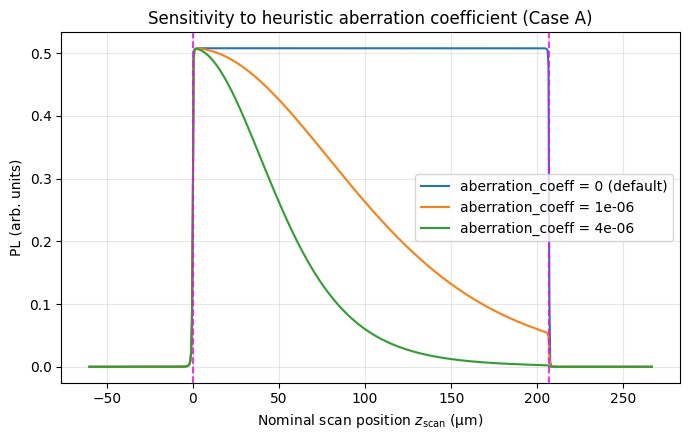

In [20]:
aberration_values = [0.0, 1e-6, 4e-6]  # um^-1; 0.0 is the notebook-wide default (Section 1)
fig, ax = plt.subplots()
for coeff in aberration_values:
    pl = compute_pl_curve(z_scan, rho_bulk, aberration_coeff_local=coeff)
    ax.plot(z_scan, pl, label=f"aberration_coeff = {coeff:.0e}" if coeff else "aberration_coeff = 0 (default)")
ax.axvline(pos2, **STYLE_INTERFACE)
ax.axvline(pos4, **STYLE_INTERFACE)
ax.set_xlabel(r"Nominal scan position $z_\mathrm{scan}$ (µm)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("Sensitivity to heuristic aberration coefficient (Case A)")
ax.legend()
plt.tight_layout()
plt.show()


## Summary

This notebook is fully parametric (Section 1) and modular (each physical effect is a standalone function):
`beam_waist` / `beam_waist_aberrated` (diffraction + optional aberration), `nominal_to_true_depth`
(index-mismatch scan mapping), `fresnel_normal_incidence` (interface losses), `local_intensity` /
`peak_intensity_W_cm2` (excitation), `rho_bulk` / `rho_layer` (NV doping geometry), and
`emission_rate_saturating` / `emission_rate_linear` (saturation), all combined in `compute_pl_curve`.
Swap in real instrument and sample parameters in Section 1 to compare against measured Z-scan data.
